# Synthetic experiment demo: a Gaussian mixture under parameter transformations

This notebook is a short, self-contained walk through the synthetic experiment.

1. The **base data** is a Gaussian mixture: 500 points in 2D drawn around 9 cluster centers.
2. Three **transformations** perturb it, each controlled by one parameter:
   - $\sigma_{noise}$ adds Gaussian noise to every point,
   - $p_{mix}$ moves points to other clusters with that probability,
   - $N_{perm}$ permutes the positions of that many cluster centers.
3. Each transformed dataset is compared with the base data through **similarity signals**: a kernel similarity $s(\sigma)$ computed with an RBF kernel at every bandwidth $\sigma$ on a log-spaced grid, rather than at one fixed bandwidth.

Everything below uses the same configuration as the full experiment (`configs/synthetic_permuted_gaussian_mds.yaml`) and the same package functions; the figures follow the paper's styling. It runs in about a minute on a CPU. The full grid, MDS embeddings, and paper figures are produced by `scripts/synthetic_sweep.py` and `scripts/paper_figures_synthetic.py` (see `docs/running_experiments.md`).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from manifold_repsim.experiments.paper_style import SIGNAL_ROW_FIGSIZE
from manifold_repsim.experiments.paper_style import SIGNAL_SHAPE_FIGSIZE
from manifold_repsim.experiments.paper_style import apply_paper_style
from manifold_repsim.experiments.paper_style import magma_ramp
from manifold_repsim.experiments.paper_style import style_signal_row
from manifold_repsim.experiments.permuted_gaussian_mds import load_config
from manifold_repsim.experiments.permuted_gaussian_mds.analysis import signal_values
from manifold_repsim.experiments.permuted_gaussian_mds.config import PARAMETER_LABELS
from manifold_repsim.experiments.permuted_gaussian_mds.config import SIGNAL_METRICS
from manifold_repsim.experiments.permuted_gaussian_mds.dataset import build_base_dataset
from manifold_repsim.experiments.permuted_gaussian_mds.dataset import transform_config
from manifold_repsim.experiments.permuted_gaussian_mds.paper_figures import PAPER_PANEL_ORDER
from manifold_repsim.experiments.permuted_gaussian_mds.paper_figures import SIGNAL_INFINITE_LIMIT
from manifold_repsim.experiments.permuted_gaussian_mds.paper_figures import SIGNAL_SHAPE_FIGURES
from manifold_repsim.experiments.permuted_gaussian_mds.paper_figures import SIGNAL_SHAPE_STYLE
from manifold_repsim.experiments.permuted_gaussian_mds.paper_figures import SIGNAL_SWEEP_METRIC_LABELS
from manifold_repsim.experiments.permuted_gaussian_mds.similarity import compute_fixed_similarity_matrix
from manifold_repsim.experiments.permuted_gaussian_mds.similarity import compute_signal_similarity_matrices
from manifold_repsim.sweeps import aggregate_signal_auc

# The package selects Matplotlib's non-interactive backend for its figure
# scripts; switch back to inline plotting for the notebook.
%matplotlib inline
apply_paper_style()

config = load_config("configs/synthetic_permuted_gaussian_mds.yaml")
sigma = signal_values(config)  # the RBF bandwidth grid, log-spaced
scratch = Path(tempfile.mkdtemp())  # memory-mapped kernel features
print(f"{len(sigma)} bandwidths from {sigma[0]:g} to {sigma[-1]:g}")

30 bandwidths from 0.005 to 5


## The base data and its transformations

`build_base_dataset` draws the Gaussian mixture from the configured seed. Each transformation is deterministic given its seed, so the same parameters always give the same dataset. Below, each panel applies one transformation at its second-largest configured level and leaves the other two at zero. Colors mark each point's original cluster, so mixing and permutation show up as colors that no longer sit together.

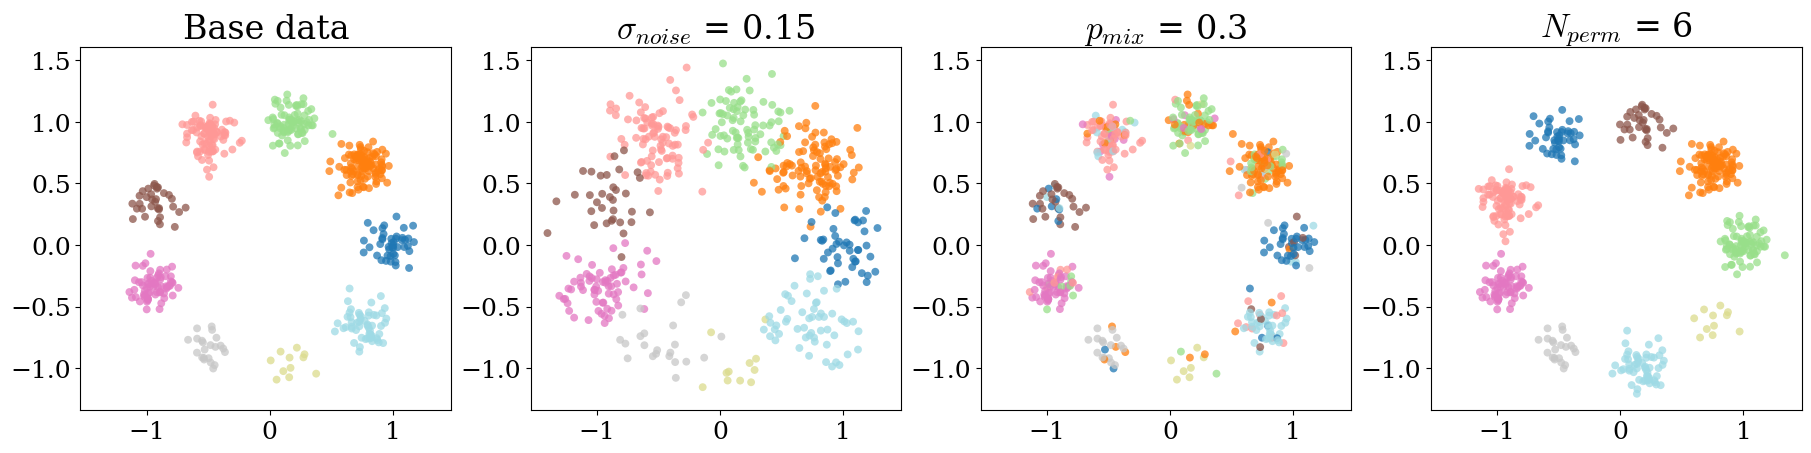

In [2]:
dataset, base = build_base_dataset(config)
labels = dataset.plot_labels


def sweep_levels(parameter):
    # Every level the configuration declares for one parameter.
    grid = config["grid"][parameter]
    if parameter == "n_permute":
        return np.asarray(sorted(set(grid["values"])))
    return np.linspace(grid["min"], grid["max"], grid["num"])


def transformed(**parameters):
    # The base data under one transformation; unlisted parameters stay at 0.
    values = {"noise_scale": 0.0, "cluster_mixing_probability": 0.0, "n_permute": 0}
    values.update(parameters)
    return dataset.transform_current(transform_config(config, **values)).copy()


examples = [("Base data", base)]
for parameter in PAPER_PANEL_ORDER:
    level = sweep_levels(parameter)[-2]
    examples.append(
        (f"{PARAMETER_LABELS[parameter]} = {level:g}", transformed(**{parameter: level}))
    )

combined = np.vstack([data for _, data in examples])
padding = np.maximum(np.ptp(combined, axis=0) * 0.05, 0.05)
low, high = combined.min(axis=0) - padding, combined.max(axis=0) + padding
cmap = plt.get_cmap("tab20", config["dataset"]["n_clusters"])

figure, axes = plt.subplots(1, 4, figsize=(18, 4.8), constrained_layout=True)
for axis, (title, data) in zip(axes, examples):
    axis.scatter(data[:, 0], data[:, 1], c=labels, cmap=cmap, s=32, alpha=0.75, linewidths=0)
    axis.set(title=title, xlim=(low[0], high[0]), ylim=(low[1], high[1]))
    axis.set_aspect("equal")
plt.show()

## Similarity signals

A similarity signal compares two representations with an RBF kernel at every bandwidth $\sigma$ on the grid, so a small $\sigma$ looks at local neighborhoods and a large $\sigma$ at global geometry. The four signals in the paper are:

| signal | kernel similarity |
|---|---|
| $s_{CKA}(\sigma)$ | centered kernel alignment |
| $s_{UKA}(\sigma)$ | uncentered kernel alignment |
| $s_{RWKA}(\sigma)$ | random-walk kernel alignment (symmetric) |
| $s_{dRWKA}(\sigma)$ | degree-corrected random-walk kernel alignment |

`signals_against_base` computes all four signals of each dataset against the base data, sharing one RBF kernel per dataset and bandwidth.

In [3]:
def signals_against_base(conditions):
    # Return {signal: array of shape (len(conditions), len(sigma))}.
    datasets = np.stack([base, *conditions])
    curves = {name: np.empty((len(conditions), len(sigma))) for name in SIGNAL_METRICS}
    for index, bandwidth in enumerate(sigma):
        matrices = compute_signal_similarity_matrices(
            datasets, list(SIGNAL_METRICS), float(bandwidth), scratch / f"{index:04d}"
        )
        for name in SIGNAL_METRICS:
            curves[name][:, index] = matrices[name][1:, 0]  # each condition vs. base
    return curves

### The shape of a signal

First, one comparison: the base data against a version with noise and permuted clusters (the configured `signal_shapes` condition). Every signal approaches 1 as $\sigma \to 0$. As $\sigma \to \infty$ the RBF kernel approaches a linear one, so $s_{CKA}$ and $s_{dRWKA}$ tend to linear CKA while $s_{UKA}$ and $s_{RWKA}$ tend to 1 (dashed lines). The informative range lies between those limits, and no single bandwidth captures it.

condition: {'cluster_mixing_probability': 0.0, 'noise_scale': 0.2, 'n_permute': 4} | linear CKA = 0.379


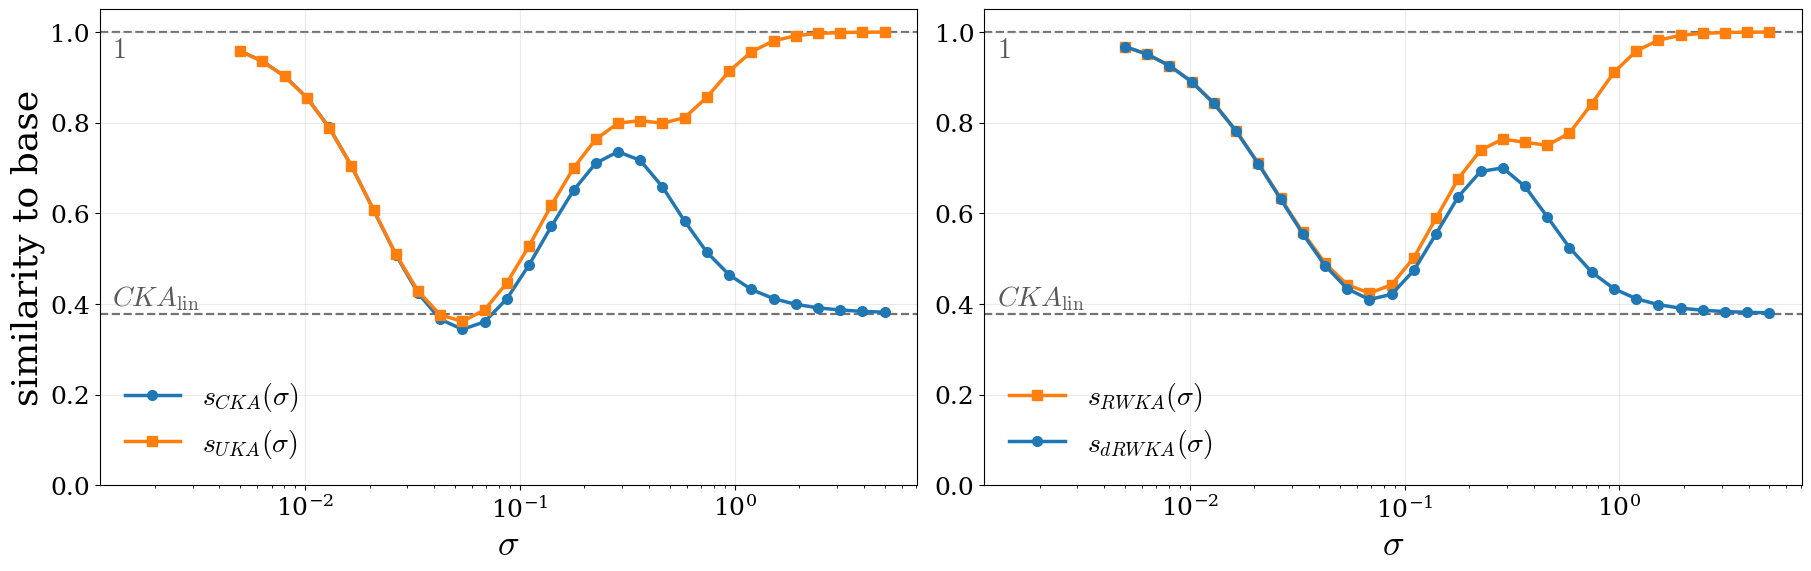

In [4]:
shape_parameters = config["metrics"]["signal_shapes"]["fixed_parameters"]
shape_condition = transformed(**shape_parameters)
shape_curves = signals_against_base([shape_condition])

linear_cka_spec = next(spec for spec in config["metrics"]["fixed"] if spec["id"] == "cka_lin")
linear_cka = compute_fixed_similarity_matrix(
    np.stack([base, shape_condition]), linear_cka_spec, scratch / "cka_lin"
)[1, 0]
print("condition:", shape_parameters, f"| linear CKA = {linear_cka:.3f}")

width, height = SIGNAL_SHAPE_FIGSIZE
figure, axes = plt.subplots(1, 2, figsize=(2 * width, height), constrained_layout=True)
for axis, (_, metrics) in zip(axes, SIGNAL_SHAPE_FIGURES):
    limits = {1.0: "$1$"}
    for metric in metrics:
        if SIGNAL_INFINITE_LIMIT[metric] == "cka_lin":
            limits[linear_cka] = r"$CKA_{\mathrm{lin}}$"
    for value, label in limits.items():
        axis.axhline(value, color="0.45", linestyle="--", linewidth=1.6, zorder=1)
        axis.annotate(
            label,
            xy=(0.015, value),
            xycoords=axis.get_yaxis_transform(),
            xytext=(0, -18 if value == 1.0 else 6),
            textcoords="offset points",
            color="0.35",
        )
    for metric in metrics:
        color, marker = SIGNAL_SHAPE_STYLE[SIGNAL_INFINITE_LIMIT[metric]]
        axis.plot(
            sigma,
            shape_curves[metric][0],
            marker=marker,
            markersize=7,
            color=color,
            linewidth=2.5,
            zorder=2,
            label=SIGNAL_SWEEP_METRIC_LABELS[metric],
        )
style_signal_row(axes, logscale=True, legend_titles=["", ""], y_label="similarity to base")
for axis in axes:
    axis.set_ylim(0.0, 1.05)
plt.show()

### How each transformation moves the signals

Now each parameter is swept over its configured levels while the other two stay at the configured `signal_sweeps` values. Each row shows one signal, and each panel shows one swept parameter, with darker curves for smaller values. The transformations act at different scales. Noise lowers the signal at small and intermediate $\sigma$, but the curves meet again at large $\sigma$. Permuting cluster centers leaves small $\sigma$ untouched and lowers the signal only at large $\sigma$. Mixing lowers it from intermediate $\sigma$ upward. A single bandwidth would see only some of these effects.

held fixed at: {'cluster_mixing_probability': 0.1, 'noise_scale': 0.2, 'n_permute': 4}


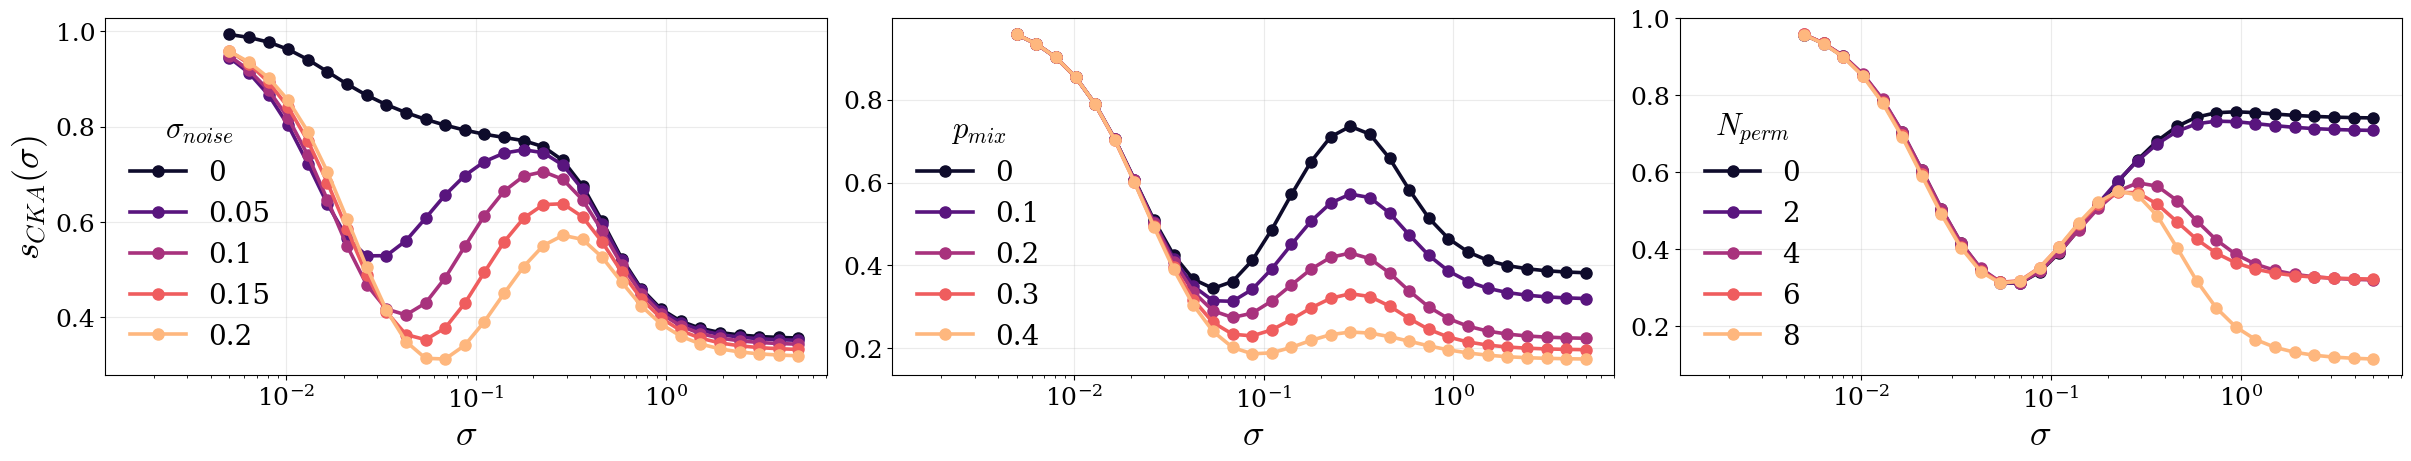

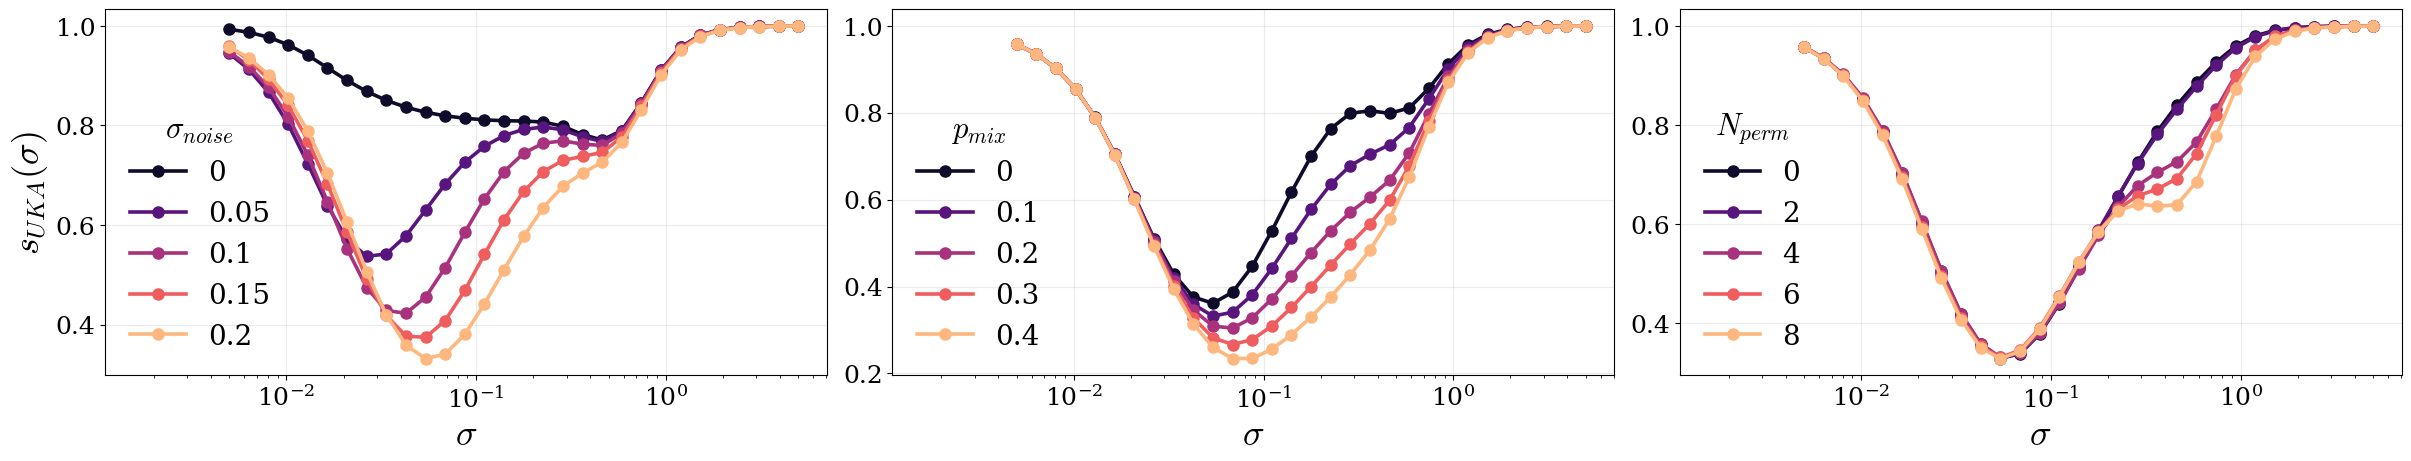

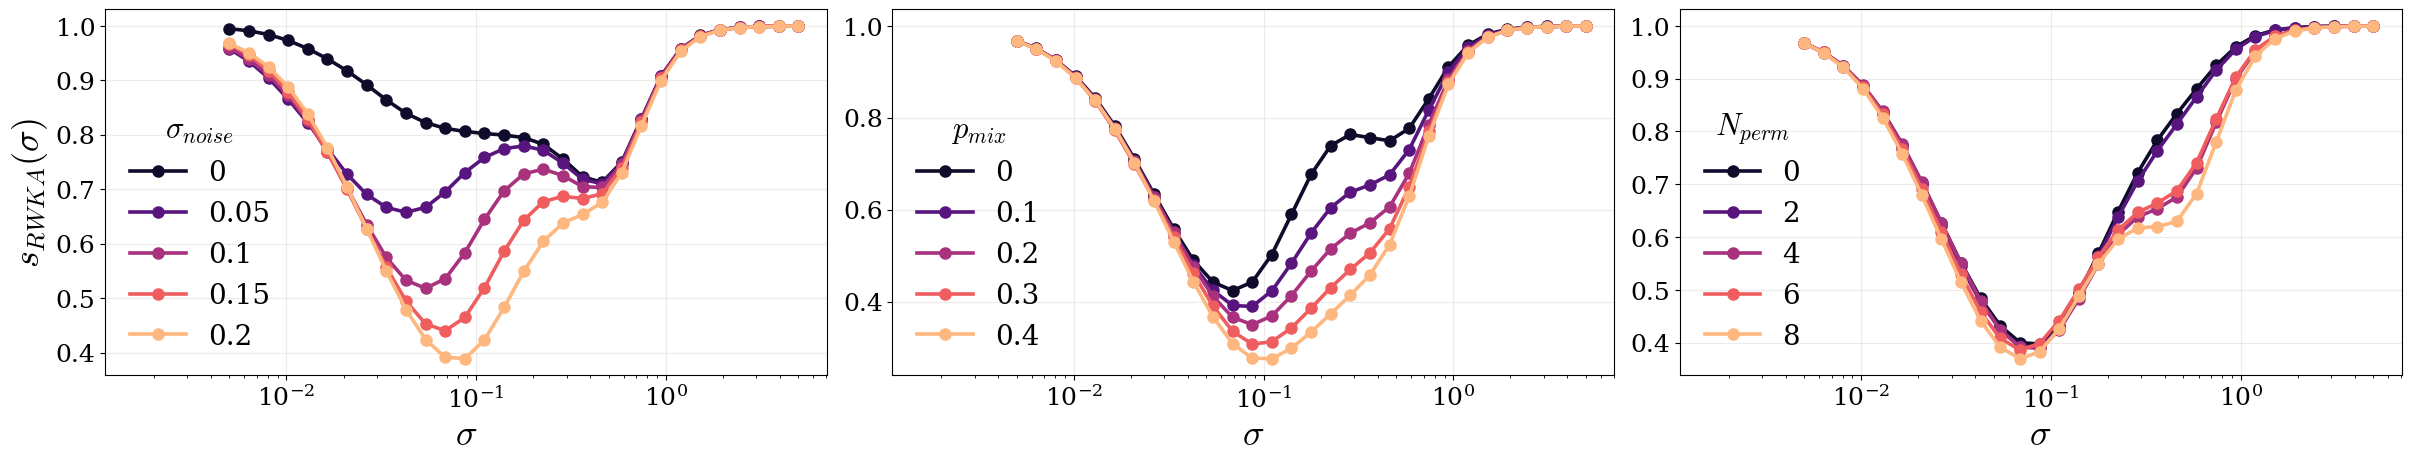

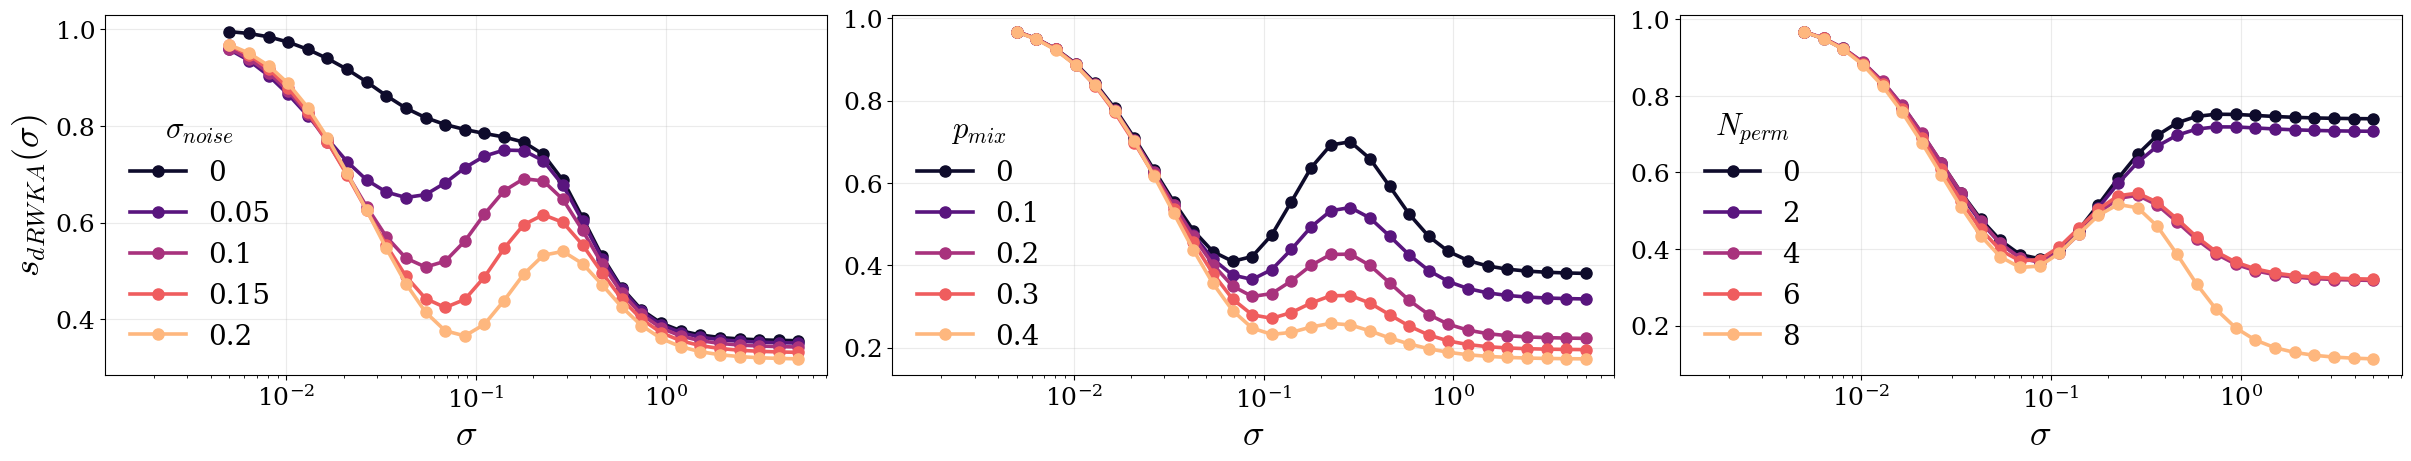

In [5]:
sweep_fixed = config["metrics"]["signal_sweeps"]["fixed_parameters"]
print("held fixed at:", sweep_fixed)

sweeps = {}
for parameter in PAPER_PANEL_ORDER:
    levels = sweep_levels(parameter)
    conditions = [transformed(**{**sweep_fixed, parameter: level}) for level in levels]
    sweeps[parameter] = (levels, signals_against_base(conditions))

for metric in SIGNAL_METRICS:
    figure, axes = plt.subplots(1, 3, figsize=SIGNAL_ROW_FIGSIZE, constrained_layout=True)
    for axis, parameter in zip(axes, PAPER_PANEL_ORDER):
        levels, curves = sweeps[parameter]
        for level, color, curve in zip(levels, magma_ramp(len(levels)), curves[metric]):
            label = f"{int(level)}" if parameter == "n_permute" else f"{level:g}"
            axis.plot(sigma, curve, marker="o", color=color, label=label)
    style_signal_row(
        axes,
        logscale=True,
        legend_titles=[PARAMETER_LABELS[parameter] for parameter in PAPER_PANEL_ORDER],
        y_label=SIGNAL_SWEEP_METRIC_LABELS[metric],
    )
    plt.show()

### Summarizing a signal by its AUC

To get a single score, a signal can be reduced to its area under the curve over the bandwidth grid. With the configured `average` aggregation, that is the mean of $s(\sigma)$ over the log-spaced grid. The table lists the AUC of each signal for every swept level.

In [6]:
integration = config["metrics"]["signals"]["integration"]
names = {"cka_rbf": "CKA", "rbf_uka": "UKA", "rbf_rwka_symmetric": "RWKA", "rbf_degree_crwka": "dRWKA"}
rows = []
for parameter in PAPER_PANEL_ORDER:
    levels, curves = sweeps[parameter]
    aucs = {
        metric: aggregate_signal_auc(sigma, curves[metric], integration)
        for metric in SIGNAL_METRICS
    }
    for index, level in enumerate(levels):
        rows.append(
            {"parameter": parameter, "level": f"{level:g}"}
            | {names[metric]: aucs[metric][index] for metric in SIGNAL_METRICS}
        )
pd.DataFrame(rows).set_index(["parameter", "level"]).round(3)

CKA    UKA   RWKA  dRWKA
parameter                  level                            
noise_scale                0      0.690  0.891  0.886  0.682
                           0.05   0.597  0.803  0.826  0.619
                           0.1    0.557  0.767  0.790  0.580
                           0.15   0.531  0.746  0.764  0.549
                           0.2    0.505  0.726  0.744  0.523
cluster_mixing_probability 0      0.568  0.759  0.777  0.582
                           0.1    0.505  0.726  0.744  0.523
                           0.2    0.436  0.695  0.719  0.464
                           0.3    0.397  0.672  0.697  0.427
                           0.4    0.365  0.652  0.681  0.401
n_permute                  0      0.647  0.745  0.772  0.678
                           2      0.637  0.744  0.766  0.662
                           4      0.505  0.726  0.744  0.523
                           6      0.497  0.721  0.744  0.523
                           8      0.432  0.712  0.728  0.448